# 08 — Sampler microbenchmark: vLLM's fused sampler vs. top-k self-conditioning

**Question:** inside a real serving engine, how much does replacing the full self-conditioning hint with a top-k hint save, in time and memory, as the batch grows?

**No model is loaded.** The sampler only needs (a) the logits and (b) the embedding table. We use real logits saved by notebook 04 and the real embedding table read from the checkpoint. This runs on **one A100**.

| path | what it does per denoising step |
|---|---|
| `vllm` | vLLM's fused Triton kernel: one pass for argmax + sample + entropy, a second pass writing the softmax in bf16; then the full hint matmul `probs @ E * sqrt(d)` (262,144 × 2,816) |
| `topk` (ours) | the same kernel **without** writing probs; then `torch.topk` + a k-row hint sum (k = 64 or 256) |
| `hf` | the Hugging Face / diffusers stock path, for reference (several full fp32 passes) |

The commit / re-noise / stop kernel is identical in `vllm` and `topk` (it only reads the 256 entropies), so it is not timed.

**What we measure**
1. **Correctness:** the copied kernel matches a float64 reference; top-k hint error vs. the full hint.
2. **Time per step** (median of 10, CUDA events) for each path and each part, at batch 1–64.
3. **Peak extra memory** each path adds on top of its inputs.
4. **Context:** the LM-head matmul time, to see the sampler's share of the step.

In [2]:
import os, sys, subprocess
if 'torch' in sys.modules:
    raise RuntimeError('Restart the kernel, then run this cell first.')
GPU = None        # e.g. '0'; None = the GPU with the most free memory
if GPU is None:
    rows = subprocess.run(['nvidia-smi', '--query-gpu=index,memory.free', '--format=csv,noheader,nounits'],
                          capture_output=True, text=True, check=True).stdout.strip().splitlines()
    free = sorted(((int(i), int(f) / 1024) for i, f in (r.split(', ') for r in rows)), key=lambda x: -x[1])
    print('free GB per GPU:', {i: round(f, 1) for i, f in free})
    GPU = str(free[0][0])
os.environ['CUDA_VISIBLE_DEVICES'] = GPU
print('using GPU', GPU)

free GB per GPU: {0: 39.5, 6: 30.4, 7: 16.1, 4: 9.9, 5: 7.6, 1: 1.0, 3: 0.5, 2: 0.5}
using GPU 0


In [3]:
import math, time, importlib
import torch, triton
import pandas as pd
import matplotlib.pyplot as plt
import hint_bench as hb          # hint_bench.py must sit next to this notebook
importlib.reload(hb)
dev = 'cuda'
print('torch', torch.__version__, '| triton', triton.__version__, '|', torch.cuda.get_device_name(0))
print('free GB:', round(torch.cuda.mem_get_info()[0] / 2**30, 1))

MODEL_ID = 'google/diffusiongemma-26B-A4B-it'
LOGITS_GLOB = './runs/nb04/step_*.pt'      # saved by notebook 04 (adjust if they live elsewhere)
CL = 256                                    # canvas length
KS = [64, 256]
BATCHES = [1, 2, 4, 8, 16, 32, 64]

torch 2.14.1+cu130 | triton 3.8.0 | NVIDIA A100-PCIE-40GB
free GB: 39.1


## 1. Inputs: the embedding table and real logits

In [4]:
t0 = time.time()
E, key = hb.load_embedding_table(MODEL_ID, dev)
scale = torch.tensor(E.shape[1] ** 0.5, dtype=E.dtype, device=dev)      # the decoder's embed_scale (~53)
E_sum = E.float().sum(0)
print(f'embedding table {key}: {tuple(E.shape)} {E.dtype}, {E.numel() * 2 / 2**30:.2f} GB, loaded in {time.time() - t0:.0f}s')

saved = hb.load_saved_logits(LOGITS_GLOB)
assert saved, f'no logits found at {LOGITS_GLOB}'
print(len(saved), 'saved steps:', [(tuple(L.shape), s) for L, s in saved])
V = E.shape[0]
assert saved[0][0].shape[-1] == V

/data/users/shreenis/private/VLA_experiments/.venv-2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


embedding table model.decoder.embed_tokens.weight: (262144, 2816) torch.bfloat16, 1.38 GB, loaded in 3s
6 saved steps: [((256, 262144), 0), ((256, 262144), 1), ((256, 262144), 2), ((256, 262144), 3), ((256, 262144), 4), ((256, 262144), 5)]


## 2. Correctness

* The copied vLLM kernel's entropy and argmax vs. a float64 reference (should agree to ~1e-5).
* The top-k hint vs. vLLM's full hint, as relative error per slot (‖topk − full‖ / ‖full‖), for each k and tail option. Notebook 07 measured ~0.2–0.5% at k = 64 against the Hugging Face hint.

In [5]:
L, temps = hb.make_batch(saved, 4, CL, dev)
inv = (1 / temps).repeat_interleave(CL)[:, None]
ref_lp = torch.log_softmax(L.double() * inv.double(), -1)
ref_ent = -(ref_lp.exp() * ref_lp).sum(-1)
argmax, sample, ent, lse, probs = hb.row_stats(L, temps, CL, probs_dtype=E.dtype)
print('entropy  max |kernel - float64|:', float((ent.double() - ref_ent).abs().max()))
print('lse      max |kernel - float64|:', float((lse.double() - torch.logsumexp(L.double() * inv.double(), -1)).abs().max()))
print('argmax   mismatches:', int((argmax != L.argmax(-1)).sum()), 'of', L.shape[0], '(ties in bf16-derived logits can differ)')
del ref_lp

full = hb.path_vllm(L, temps, CL, E, scale)['hint'].float()
nf = full.norm(dim=-1).clamp_min(1e-6)
rows = []
for k in KS:
    for tail in ('drop', 'renorm', 'mean'):
        h = hb.topk_hint(L, temps, CL, lse, E, scale, k, tail, E_sum).float()
        rel = ((h - full).norm(dim=-1) / nf)
        rows.append(dict(k=k, tail=tail, rel_err_mean_pct=100 * float(rel.mean()), rel_err_p99_pct=100 * float(rel.quantile(0.99))))
print(pd.DataFrame(rows).to_string(index=False, float_format='{:.3f}'.format))
del L, full, probs

entropy  max |kernel - float64|: 8.447572670267078e-07
lse      max |kernel - float64|: 2.4992759719566493e-06
argmax   mismatches: 0 of 1024 (ties in bf16-derived logits can differ)
  k   tail  rel_err_mean_pct  rel_err_p99_pct
 64   drop             0.097            1.054
 64 renorm             0.090            0.762
 64   mean             0.096            1.015
256   drop             0.069            0.374
256 renorm             0.070            0.389
256   mean             0.069            0.374


## 3. Time and memory vs. batch size

For each batch size B (B sequences × 256 slots), we build the logits once and time each path and its parts. If a path runs out of memory it is recorded as `OOM`; that is a result, not an error. Inputs alone take B × 268 MB, so B = 64 needs ~17 GB before any path runs.

In [6]:
RUN_HF = True        # the stock path needs several full fp32 copies; it will OOM at large B
results = []
for B in BATCHES:
    need = B * CL * V * 4 / 2**30
    if need * 1.6 > torch.cuda.mem_get_info()[0] / 2**30:
        print(f'B={B}: skipped (inputs alone {need:.1f} GB)'); continue
    L, temps = hb.make_batch(saved, B, CL, dev)
    _, _, _, lse, _ = hb.row_stats(L, temps, CL)
    row = dict(B=B)
    tests = {
        'vllm_total':        lambda: hb.path_vllm(L, temps, CL, E, scale),
        'vllm_stats+probs':  lambda: hb.row_stats(L, temps, CL, probs_dtype=E.dtype),
        'stats_only':        lambda: hb.row_stats(L, temps, CL),
    }
    probs_once = hb.row_stats(L, temps, CL, probs_dtype=E.dtype)[4]
    tests['vllm_hint_matmul'] = lambda: torch.matmul(probs_once, E) * scale
    for k in KS:
        tests[f'topk{k}_total'] = (lambda k=k: hb.path_topk(L, temps, CL, E, scale, k, 'renorm'))
        tests[f'topk{k}_topk'] = (lambda k=k: torch.topk(L, k, dim=-1))
        tests[f'topk{k}_hint'] = (lambda k=k: hb.topk_hint(L, temps, CL, lse, E, scale, k, 'renorm'))
    if RUN_HF:
        tests['hf_total'] = lambda: hb.path_hf(L, temps, CL, E, scale)
    hidden = torch.randn(B * CL, E.shape[1], dtype=E.dtype, device=dev)
    tests['context_lm_head'] = lambda: torch.matmul(hidden, E.t())
    for name, fn in tests.items():
        try:
            row[name + '_ms'] = hb.time_cuda(fn)
            if name.endswith('_total') or name == 'context_lm_head':
                row[name + '_mem_gb'] = hb.peak_extra_gb(fn)
        except torch.OutOfMemoryError:
            row[name + '_ms'] = float('nan'); row[name + '_mem_gb'] = float('nan')
            torch.cuda.empty_cache()
    del probs_once, hidden, L
    torch.cuda.empty_cache()
    results.append(row)
    print(f"B={B:3d} | vllm {row['vllm_total_ms']:7.2f} ms | topk64 {row['topk64_total_ms']:7.2f} ms | "
          f"hf {row.get('hf_total_ms', float('nan')):7.2f} ms | LM head {row['context_lm_head_ms']:7.2f} ms")
res = pd.DataFrame(results)
os.makedirs('./runs/nb08', exist_ok=True)
res.to_csv('./runs/nb08/sampler_bench.csv', index=False)

B=  1 | vllm    4.95 ms | topk64    4.74 ms | hf   15.00 ms | LM head    1.70 ms
B=  2 | vllm    5.51 ms | topk64    5.71 ms | hf   28.73 ms | LM head    3.60 ms
B=  4 | vllm   10.97 ms | topk64   10.11 ms | hf   56.07 ms | LM head    7.49 ms
B=  8 | vllm   21.18 ms | topk64   19.33 ms | hf  111.42 ms | LM head   16.50 ms
B= 16 | vllm   43.89 ms | topk64   38.57 ms | hf  223.48 ms | LM head   28.24 ms


[W1124 01:43:33.834493451 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 8589934592 bytes (free: 1446051840, total: 42404806656).
[W1124 01:43:33.882992839 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 8589934592 bytes (free: 1538326528, total: 42404806656).


B= 32 | vllm   93.32 ms | topk64   81.58 ms | hf     nan ms | LM head   57.14 ms


[W1124 01:43:56.891785633 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 17179869184 bytes (free: 14085586944, total: 42404806656).
[W1124 01:43:56.904060389 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 17179869184 bytes (free: 14423228416, total: 42404806656).


B= 64 | vllm  201.52 ms | topk64  162.87 ms | hf     nan ms | LM head  114.24 ms


## 4. Results

In [7]:
pd.set_option('display.float_format', '{:.2f}'.format)
cols = ['B', 'vllm_total_ms', 'topk64_total_ms', 'topk256_total_ms', 'hf_total_ms', 'context_lm_head_ms']
print('Time per denoising step (ms)')
print(res[[c for c in cols if c in res]].to_string(index=False))

print('\nWhere vLLM\'s time goes (ms)')
print(res[['B', 'stats_only_ms', 'vllm_stats+probs_ms', 'vllm_hint_matmul_ms']].to_string(index=False))
print('\nWhere top-k\'s time goes (ms)')
print(res[['B', 'stats_only_ms', 'topk64_topk_ms', 'topk64_hint_ms']].to_string(index=False))

s = pd.DataFrame({'B': res.B,
                  'speedup vs vllm (k=64)': res.vllm_total_ms / res.topk64_total_ms,
                  'speedup vs vllm (k=256)': res.vllm_total_ms / res.topk256_total_ms,
                  'saved ms/step (k=64)': res.vllm_total_ms - res.topk64_total_ms,
                  'saved as % of LM head': 100 * (res.vllm_total_ms - res.topk64_total_ms) / res.context_lm_head_ms})
print('\nSummary'); print(s.to_string(index=False))

print('\nPeak extra memory per step (GB)')
mcols = ['B', 'vllm_total_mem_gb', 'topk64_total_mem_gb', 'topk256_total_mem_gb', 'hf_total_mem_gb']
print(res[[c for c in mcols if c in res]].to_string(index=False))

Time per denoising step (ms)
 B  vllm_total_ms  topk64_total_ms  topk256_total_ms  hf_total_ms  context_lm_head_ms
 1           4.95             4.74              3.45        15.00                1.70
 2           5.51             5.71              5.93        28.73                3.60
 4          10.97            10.11             11.58        56.07                7.49
 8          21.18            19.33             22.54       111.42               16.50
16          43.89            38.57             45.33       223.48               28.24
32          93.32            81.58             95.20          NaN               57.14
64         201.52           162.87            190.31          NaN              114.24

Where vLLM's time goes (ms)
 B  stats_only_ms  vllm_stats+probs_ms  vllm_hint_matmul_ms
 1           2.04                 2.38                 2.60
 2           1.94                 2.55                 2.87
 4           3.68                 4.64                 6.77
 8           6

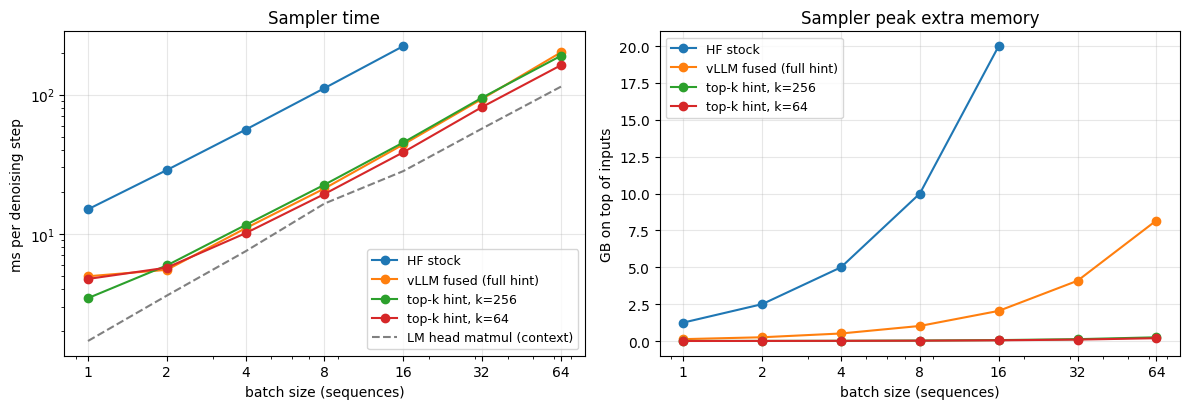

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, lab in [('hf_total', 'HF stock'), ('vllm_total', 'vLLM fused (full hint)'),
                  ('topk256_total', 'top-k hint, k=256'), ('topk64_total', 'top-k hint, k=64')]:
    if name + '_ms' in res:
        ax[0].plot(res.B, res[name + '_ms'], marker='o', label=lab)
        ax[1].plot(res.B, res[name + '_mem_gb'], marker='o', label=lab)
ax[0].plot(res.B, res.context_lm_head_ms, ls='--', color='gray', label='LM head matmul (context)')
ax[0].set(xscale='log', yscale='log', xlabel='batch size (sequences)', ylabel='ms per denoising step', title='Sampler time')
ax[1].set(xscale='log', xlabel='batch size (sequences)', ylabel='GB on top of inputs', title='Sampler peak extra memory')
for a in ax:
    a.set_xticks(res.B); a.set_xticklabels(res.B); a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.savefig('./runs/nb08/sampler_bench.png', dpi=150); plt.show()

## How to read the results

1. **Correctness first.** The kernel's entropy must match float64 to ~1e-5, and the top-k hint error should be well under 1% at k = 64 (renorm best). If not, stop and check.
2. **The headline is `speedup vs vllm` and `saved ms/step`.** vLLM's time is mostly two things: the bf16 probs write (`vllm_stats+probs` − `stats_only`) and the hint matmul. Top-k removes both and adds `topk` + a tiny `hint`.
3. **`saved as % of LM head`** puts the saving in context: the LM-head matmul is a fixed part of every step. A saving comparable to the LM head is a large fraction of the whole step.
4. **Memory:** vLLM keeps a [B·256 × 262,144] bf16 probs tensor (134 MB per sequence); top-k keeps [B·256 × k].
5. **What this does not include:** the 30 layers. The end-to-end effect is measured later inside vLLM (tensor parallel 2), where `saved ms/step` is compared with the full step time.
6. **Known extra cost in `topk`:** `torch.topk` reads the logits a second time. Folding the top-k into the stats kernel (one pass) is the next step; `topk64_topk_ms` is the most that would save.